# Beach Human Detection — Four Preprocessing Methods + 100-Epoch Training


This notebook uses **batch size 8** and trains **one new Faster R-CNN ResNet-50 FPN v2 model for 100 epochs total** using the new Roboflow BHD v1 dataset. It does **not** load, modify, or mix in the existing `fasterrcnn_best.pth` checkpoint.

Required semantic classes: `0 = Human on Land`, `1 = Human in Water`.

During training, each image is randomly processed using one of four methods: CLAHE, Gaussian blur, Median filtering, or Bilateral filtering. The same trained model is then evaluated on test images transformed separately by each method. The notebook produces one before/after comparison per method, metric graphs, and 10 test-image visualizations per method.

**Credential safety:** the API key pasted into chat should be rotated. Enter the replacement key securely when prompted; it is not embedded in this notebook.

## 1. Install dependencies and check GPU

In [ ]:
!pip -q install roboflow opencv-python-headless matplotlib pandas pyyaml tqdm torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 80.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.0 MB/s eta 0:00:00


In [ ]:
import os, time, random, getpass, zipfile
from pathlib import Path
import cv2, yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch, torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import functional as TF
from torchmetrics.detection.mean_ap import MeanAveragePrecision

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch:", torch.__version__, "Torchvision:", torchvision.__version__, "Device:", DEVICE)
if DEVICE.type != "cuda": print("WARNING: enable a GPU for one 100-epoch run.")

Torch: 2.11.0+cu130 Torchvision: 0.26.0+cu130 Device: cuda


## 2. Download Roboflow dataset (YOLOv8 format)

In [ ]:
from roboflow import Roboflow
ROBOFLOW_API_KEY = getpass.getpass("Roboflow API key (input hidden): ").strip()
if not ROBOFLOW_API_KEY: raise ValueError("Roboflow API key is required.")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("image-analysis-project-rfnyq").project("bhd-m9qqy")
version = project.version(1)
dataset = version.download("yolov8")
DATASET_DIR = Path(dataset.location)
yaml_files = list(DATASET_DIR.rglob("data.yaml"))
if not yaml_files: raise FileNotFoundError(f"data.yaml not found under {DATASET_DIR}")
YAML_PATH = yaml_files[0]
with open(YAML_PATH, encoding="utf-8") as f: CFG = yaml.safe_load(f)
ROOT = YAML_PATH.parent
print("Dataset:", DATASET_DIR, "\nConfig:", CFG)

Roboflow API key (input hidden): ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to bhd-1 in yolov8:: 100%|██████████| 479/479 [00:00<00:00, 8314.76it/s]

Dataset: /content/bhd-1 
Config: {'names': ['0', '1'], 'nc': 2, 'roboflow': {'license': 'CC BY 4.0', 'project': 'bhd-m9qqy', 'url': 'https://universe.roboflow.com/image-analysis-project-rfnyq/bhd-m9qqy/dataset/1', 'version': 1, 'workspace': 'image-analysis-project-rfnyq'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


## 3. Validate and map class names
The source class order is checked instead of assumed. The code stops if names cannot be mapped unambiguously.

In [ ]:
# Explicit class mapping for the Roboflow dataset
# Confirm these IDs match your dataset's actual annotations.

land = 0
water = 1

SOURCE_TO_SEMANTIC = {
    land: 0,   # Human on Land
    water: 1   # Human in Water
}

# Faster R-CNN reserves label 0 for background
SEMANTIC_TO_TORCHVISION = {
    0: 1,      # Human on Land
    1: 2       # Human in Water
}

print("Class mapping configured successfully:")
print("Dataset class 0 -> Human on Land -> Faster R-CNN label 1")
print("Dataset class 1 -> Human in Water -> Faster R-CNN label 2")

Class mapping configured successfully:
Dataset class 0 -> Human on Land -> Faster R-CNN label 1
Dataset class 1 -> Human in Water -> Faster R-CNN label 2


## 4. Find image splits and annotation files

In [ ]:
EXTS={".jpg",".jpeg",".png",".bmp",".webp"}
def split_dir(split):
    cfg=CFG.get(split)
    candidates=[]
    if cfg:
        p=Path(cfg); candidates += [p if p.is_absolute() else ROOT/p, p if p.is_absolute() else DATASET_DIR/p]
    candidates += [ROOT/split/"images", ROOT/split, DATASET_DIR/split/"images", DATASET_DIR/split]
    for p in candidates:
        if p.exists() and p.is_dir() and p.name.lower()!="labels" and any(x.suffix.lower() in EXTS for x in p.rglob("*")):
            return p
    return None
SPLITS={s:split_dir(s) for s in ["train","valid","test"]}
print({k:str(v) if v else None for k,v in SPLITS.items()})
if SPLITS["train"] is None: raise FileNotFoundError("Training image folder not found; inspect CFG and downloaded dataset structure.")
if SPLITS["valid"] is None: print("WARNING: validation split missing.")
if SPLITS["test"] is None: print("WARNING: test split missing; validation split will be used for final metrics.")
def imgs(folder): return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in EXTS)
def label_for(image_path):
    for parent in [image_path.parent,*image_path.parents]:
        if parent.name.lower()=="images":
            q=parent.parent/"labels"/image_path.relative_to(parent).with_suffix(".txt")
            if q.exists(): return q
    q=image_path.parent.parent/"labels"/(image_path.stem+".txt")
    if q.exists(): return q
    q=image_path.with_suffix(".txt")
    return q if q.exists() else None
for s,p in SPLITS.items():
    if p: print(s, len(imgs(p)), "images")

{'train': '/content/bhd-1/train/images', 'valid': '/content/bhd-1/valid/images', 'test': '/content/bhd-1/test/images'}
train 166 images
valid 47 images
test 24 images


## 5. Four preprocessing methods and individual before/after comparisons

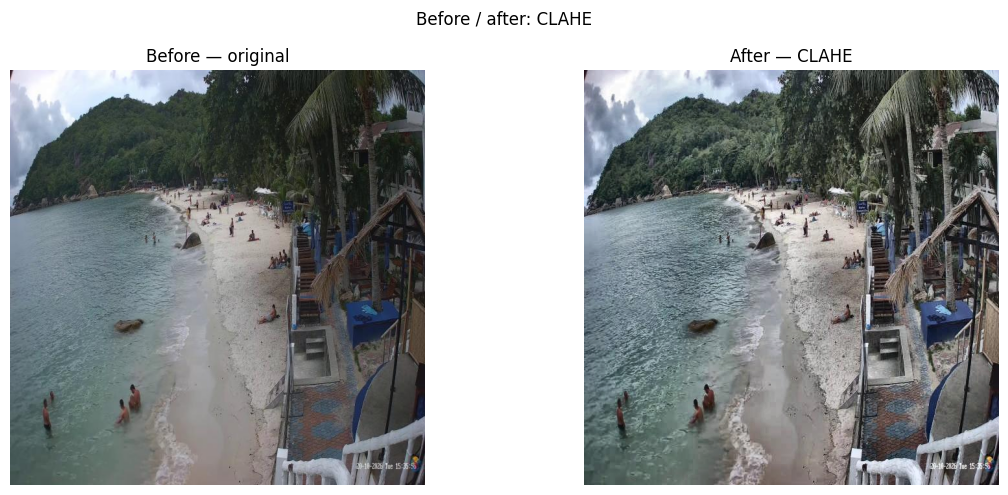

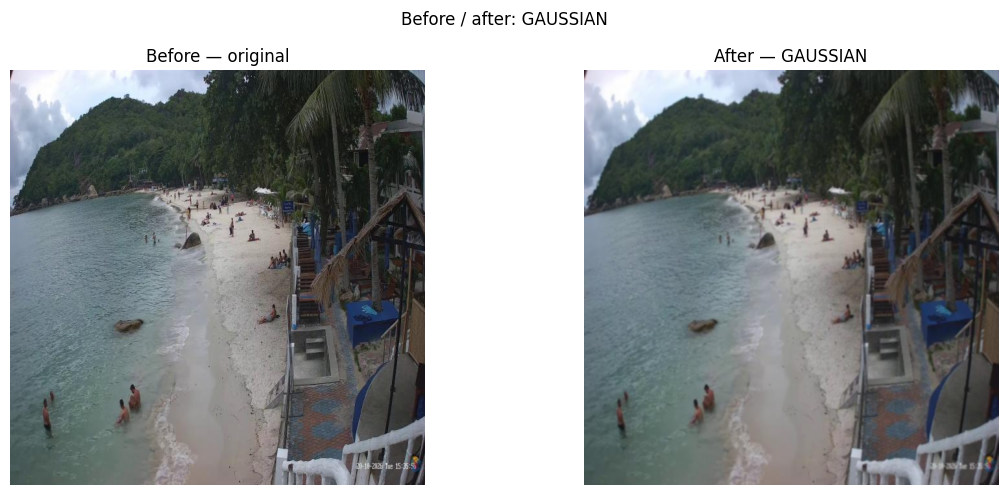

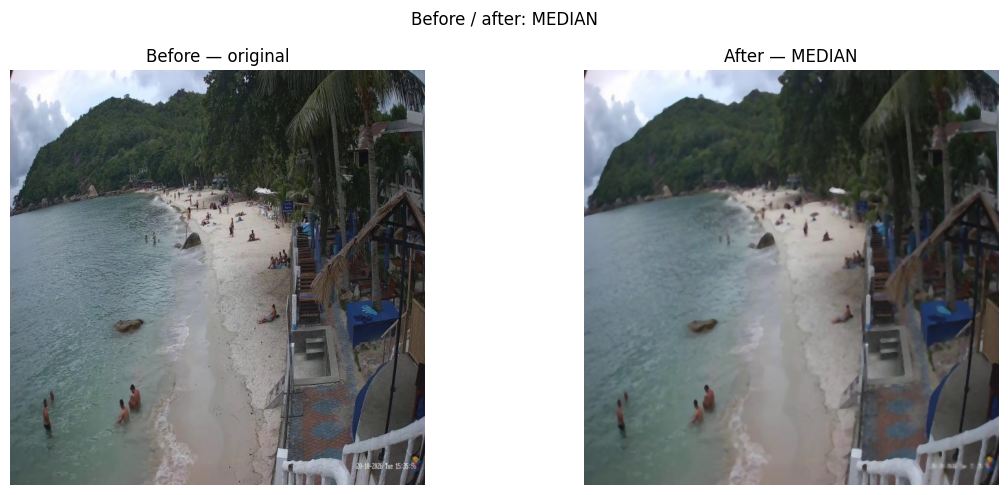

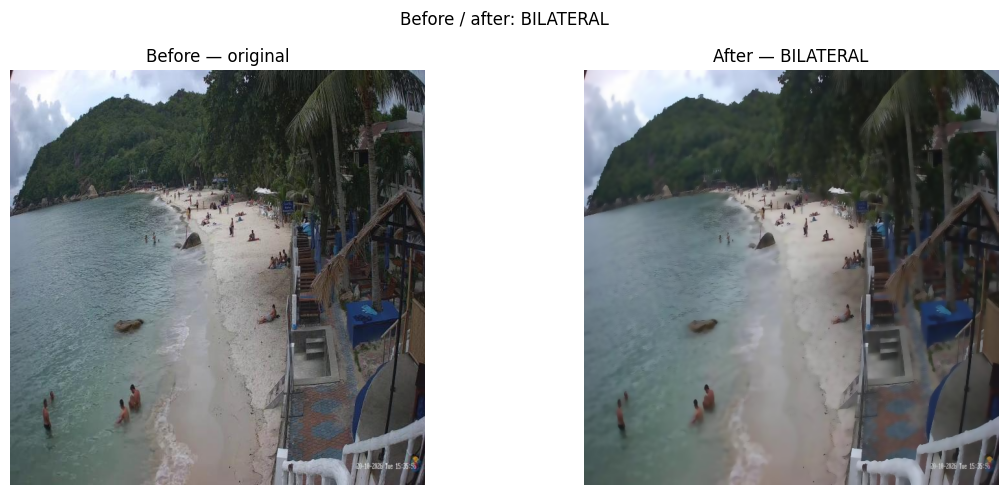

In [ ]:
METHODS=["clahe","gaussian","median","bilateral"]
def preprocess(bgr, method):
    if method=="original": return bgr.copy()
    if method=="clahe":
        lab=cv2.cvtColor(bgr,cv2.COLOR_BGR2LAB); l,a,b=cv2.split(lab)
        l=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(l)
        return cv2.cvtColor(cv2.merge((l,a,b)),cv2.COLOR_LAB2BGR)
    if method=="gaussian": return cv2.GaussianBlur(bgr,(5,5),0)
    if method=="median": return cv2.medianBlur(bgr,5)
    if method=="bilateral": return cv2.bilateralFilter(bgr,9,75,75)
    raise ValueError(method)

sample_files=imgs(SPLITS["train"])
if not sample_files: raise ValueError("No training images found.")
sample_path=sample_files[0]
bgr=cv2.imread(str(sample_path))
if bgr is None: raise ValueError(f"Cannot read {sample_path}")
original=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
for method in METHODS:
    after=cv2.cvtColor(preprocess(bgr,method),cv2.COLOR_BGR2RGB)
    fig,ax=plt.subplots(1,2,figsize=(12,5))
    ax[0].imshow(original); ax[0].set_title("Before — original"); ax[0].axis("off")
    ax[1].imshow(after); ax[1].set_title("After — "+method.upper()); ax[1].axis("off")
    fig.suptitle(f"Before / after: {method.upper()}"); plt.tight_layout(); plt.show()

## 6. YOLO annotation conversion and dataset loader

YOLO boxes are normalized center-width-height values; this converts them to absolute `xyxy` coordinates. Class mapping is validated. **Torchvision uses label 0 for background**, so internally the model uses 1 for Human on Land and 2 for Human in Water; displayed semantic IDs remain 0 and 1. Image dimensions do not change during preprocessing, so ground-truth boxes remain aligned.

In [ ]:
def parse_labels(path,w,h):
    boxes=[]; labels=[]
    if path is None: return boxes,labels
    txt=path.read_text(encoding="utf-8").strip()
    if not txt: return boxes,labels
    for ln,line in enumerate(txt.splitlines(),1):
        v=line.split()
        if len(v)!=5: raise ValueError(f"Expected 5 YOLO values at {path}:{ln}")
        src=int(float(v[0]))
        if src not in SOURCE_TO_SEMANTIC: raise ValueError(f"Unexpected class id {src} at {path}:{ln}")
        xc,yc,bw,bh=map(float,v[1:])
        if not np.isfinite([xc,yc,bw,bh]).all() or bw<=0 or bh<=0: raise ValueError(f"Invalid box {path}:{ln}")
        x1=max(0,(xc-bw/2)*w); y1=max(0,(yc-bh/2)*h)
        x2=min(w,(xc+bw/2)*w); y2=min(h,(yc+bh/2)*h)
        if x2<=x1 or y2<=y1: raise ValueError(f"Degenerate box {path}:{ln}")
        boxes.append([x1,y1,x2,y2]); labels.append(SOURCE_TO_SEMANTIC[src]+1)
    return boxes,labels

class BHDDataset(Dataset):
    def __init__(self, folder, method):
        self.folder=Path(folder); self.files=imgs(folder); self.method=method
        if not self.files: raise ValueError(f"No images in {folder}")
    def __len__(self): return len(self.files)
    def __getitem__(self,i):
        p=self.files[i]; bgr=cv2.imread(str(p))
        if bgr is None: raise ValueError(f"Unreadable image {p}")
        # Randomly choose one preprocessing method on each training image visit.
        method=random.choice(METHODS) if self.method=="combined" else self.method
        bgr=preprocess(bgr,method); h,w=bgr.shape[:2]
        rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
        boxes,labels=parse_labels(label_for(p),w,h)
        target={"boxes":torch.tensor(boxes,dtype=torch.float32).reshape(-1,4),
                "labels":torch.tensor(labels,dtype=torch.int64),
                "image_id":torch.tensor([i]),
                "area":torch.tensor([(b[2]-b[0])*(b[3]-b[1]) for b in boxes],dtype=torch.float32),
                "iscrowd":torch.zeros(len(boxes),dtype=torch.int64)}
        return TF.to_tensor(Image.fromarray(rgb)),target
def collate(batch): return tuple(zip(*batch))

for pth in sample_files[:min(25,len(sample_files))]:
    im=cv2.imread(str(pth))
    if im is None: raise ValueError(f"Unreadable image {pth}")
    parse_labels(label_for(pth),im.shape[1],im.shape[0])
print("Annotation sanity checks passed.")

Annotation sanity checks passed.


## 7. Training setup — one combined model, 100 epochs total

The training loader randomly applies one of the four preprocessing techniques on each image visit. One new model is trained for **100 epochs total**, not 100 epochs per method. The existing project checkpoint is not loaded. The configured batch size is **8**; use a GPU runtime for practical training speed and memory use.

In [ ]:
# Re-establish DEVICE here as well, so this cell still works after a Colab runtime reset.
import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type != "cuda":
    print("WARNING: GPU is not enabled. Batch size 8 on CPU can be very slow or run out of memory.")
    print("In Colab, choose Runtime > Change runtime type > T4 GPU, save, then run the notebook from the top.")

NUM_EPOCHS = 100
BATCH_SIZE = 8
NUM_WORKERS = 2
LR = 0.005
OUT = Path("/content/BHD_new_dataset_results")
OUT.mkdir(parents=True, exist_ok=True)
METHODS = ["clahe", "gaussian", "median", "bilateral"]

def build_model():
    weights = torchvision.models.detection.FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    m = fasterrcnn_resnet50_fpn_v2(weights=weights)
    in_features = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(in_features, 3)
    return m.to(DEVICE)

def loader(folder, method, shuffle=False):
    return DataLoader(
        BHDDataset(folder, method),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        collate_fn=collate,
        pin_memory=DEVICE.type == "cuda"
    )

def train_epoch(model, dl, opt, epoch):
    model.train()
    total = 0
    for images, targets in tqdm(dl, desc=f"combined {epoch+1}/{NUM_EPOCHS}", leave=False):
        images = [x.to(DEVICE) for x in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        losses = model(images, targets)
        loss = sum(losses.values())
        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss: {losses}")
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        opt.step()
        total += float(loss.detach().cpu())
    return total / max(len(dl), 1)

@torch.no_grad()
def val_loss(model, dl):
    if dl is None:
        return float("nan")
    was = model.training
    # Torchvision detection models return losses in training mode.
    model.train()
    total = 0
    n = 0
    for images, targets in dl:
        images = [x.to(DEVICE) for x in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        losses = model(images, targets)
        loss = sum(losses.values())
        if torch.isfinite(loss):
            total += float(loss.cpu())
            n += 1
    model.train(was)
    return total / max(n, 1)

print("Batch size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)
print("Output directory:", OUT)


Device: cuda
Batch size: 8
Epochs: 100
Output directory: /content/BHD_new_dataset_results


## 8. Train one new model for 100 epochs total

The same model sees all four preprocessing methods during training. A fresh model is initialized; no existing project checkpoint is loaded. A checkpoint is saved after every epoch.

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 182MB/s]


combined 1/100:   0%|          | 0/21 [00:00<?, ?it/s]

Epoch 001/100: train_loss=1.5816, val_loss=1.1550


combined 2/100:   0%|          | 0/21 [00:00<?, ?it/s]

...

Epoch 098/100: train_loss=0.2607, val_loss=0.6503


combined 99/100:   0%|          | 0/21 [00:00<?, ?it/s]

Epoch 099/100: train_loss=0.2582, val_loss=0.6533


combined 100/100:   0%|          | 0/21 [00:00<?, ?it/s]

Epoch 100/100: train_loss=0.2581, val_loss=0.6543


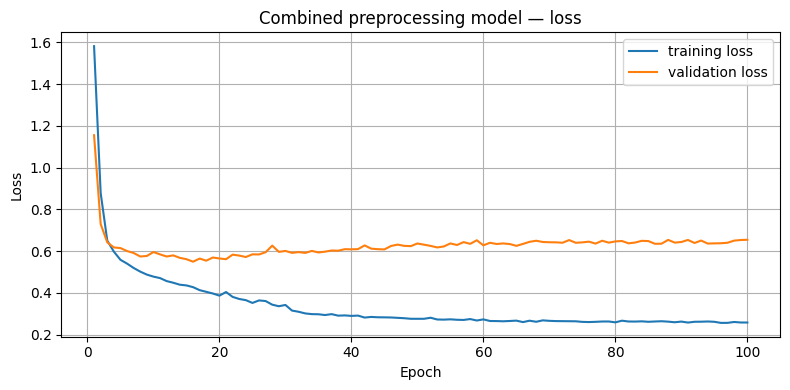

Training complete: one model, 100 epochs total.


In [ ]:
train_dl=loader(SPLITS["train"],"combined",True)
val_dl=loader(SPLITS["valid"],"original",False) if SPLITS["valid"] else None
model=build_model()
optimizer=torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                          lr=LR,momentum=0.9,weight_decay=0.0005)
scheduler=torch.optim.lr_scheduler.StepLR(optimizer,step_size=30,gamma=0.1)
history=[]; best_val=float("inf")
checkpoint_dir=OUT/"combined_model"; checkpoint_dir.mkdir(parents=True,exist_ok=True)

for epoch in range(NUM_EPOCHS):
    tr_loss=train_epoch(model,train_dl,optimizer,epoch)
    va_loss=val_loss(model,val_dl) if val_dl is not None else float("nan")
    scheduler.step()
    history.append({"epoch":epoch+1,"train_loss":tr_loss,"val_loss":va_loss})
    torch.save({"epoch":epoch+1,"model_state_dict":model.state_dict(),
                "optimizer_state_dict":optimizer.state_dict(),"history":history},
               checkpoint_dir/"last_checkpoint.pth")
    if val_dl is None or (np.isfinite(va_loss) and va_loss<best_val):
        if val_dl is not None: best_val=va_loss
        torch.save(model.state_dict(),checkpoint_dir/"best_model_state_dict.pth")
    print(f"Epoch {epoch+1:03d}/{NUM_EPOCHS}: train_loss={tr_loss:.4f}, val_loss={va_loss:.4f}")

pd.DataFrame(history).to_csv(checkpoint_dir/"training_history.csv",index=False)
hdf=pd.DataFrame(history)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(hdf.epoch,hdf.train_loss,label="training loss")
if hdf.val_loss.notna().any(): ax.plot(hdf.epoch,hdf.val_loss,label="validation loss")
ax.set_title("Combined preprocessing model — loss"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.grid(True); ax.legend(); plt.tight_layout(); fig.savefig(OUT/"combined_training_loss.png",dpi=150); plt.show()
model.load_state_dict(torch.load(checkpoint_dir/"best_model_state_dict.pth",map_location=DEVICE))
model.eval()
print("Training complete: one model, 100 epochs total.")

## 9. Evaluate the same trained model on each preprocessing method

The same combined-trained model is tested on held-out images transformed separately with CLAHE, Gaussian, Median, and Bilateral filtering. This compares test-time preprocessing effects, not four independently trained models.

In [ ]:
EVAL_DIR=SPLITS["test"] or SPLITS["valid"]
if EVAL_DIR is None: raise FileNotFoundError("Neither test nor validation split exists.")
print("Evaluation split:",EVAL_DIR)

def ious(box, boxes):
    if len(boxes)==0: return np.zeros(0)
    x1=np.maximum(box[0],boxes[:,0]); y1=np.maximum(box[1],boxes[:,1])
    x2=np.minimum(box[2],boxes[:,2]); y2=np.minimum(box[3],boxes[:,3])
    inter=np.maximum(0,x2-x1)*np.maximum(0,y2-y1)
    a=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    b=np.maximum(0,boxes[:,2]-boxes[:,0])*np.maximum(0,boxes[:,3]-boxes[:,1])
    return inter/np.maximum(a+b-inter,1e-9)

@torch.no_grad()
def evaluate(model,method):
    dl=loader(EVAL_DIR,method,False); model.eval()
    tp=fp=fn=0; metric=MeanAveragePrecision(box_format="xyxy",iou_type="bbox")
    for ims,ts in tqdm(dl,desc="Evaluate "+method,leave=False):
        outs=model([x.to(DEVICE) for x in ims])
        for t,o in zip(ts,outs):
            gb=t["boxes"].cpu(); gl=t["labels"].cpu()
            pb=o["boxes"].cpu(); pl=o["labels"].cpu(); sc=o["scores"].cpu()
            keep=sc>=0.5; pb,pl,sc=pb[keep],pl[keep],sc[keep]
            metric.update([{"boxes":pb,"scores":sc,"labels":pl}],[{"boxes":gb,"labels":gl}])
            used=set(); g=gb.numpy(); gln=gl.numpy()
            for box,label in zip(pb.numpy(),pl.numpy()):
                candidates=[j for j,c in enumerate(gln) if c==int(label) and j not in used]
                if candidates:
                    ov=ious(box,g[candidates]); j=int(np.argmax(ov))
                    if len(ov) and ov[j]>=0.5: tp+=1; used.add(candidates[j])
                    else: fp+=1
                else: fp+=1
            fn+=len(gln)-len(used)
    pr=tp/max(tp+fp,1); re=tp/max(tp+fn,1); f1=2*pr*re/max(pr+re,1e-12)
    mr=metric.compute()
    return {"method":method,"precision":pr,"recall":re,"F1":f1,
            "mAP50":float(mr["map_50"].cpu()),"mAP50_95":float(mr["map"].cpu()),
            "TP":tp,"FP":fp,"FN":fn,"images":len(BHDDataset(EVAL_DIR,method))}
rows=[evaluate(model,m) for m in METHODS]
metrics=pd.DataFrame(rows)
display(metrics)
metrics.to_csv(OUT/"metrics_comparison.csv",index=False)

Evaluation split: /content/bhd-1/test/images


Evaluate clahe:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluate gaussian:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluate median:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluate bilateral:   0%|          | 0/3 [00:00<?, ?it/s]

,method,precision,recall,F1,mAP50,mAP50_95,TP,FP,FN,images
0,clahe,0.572414,0.958430,0.716753,0.912616,0.544633,415,310,18,24
1,gaussian,0.547872,0.951501,0.695359,0.898874,0.544474,412,340,21,24
2,median,0.569405,0.928406,0.705882,0.880425,0.517350,402,304,31,24
3,bilateral,0.591105,0.951501,0.729204,0.913324,0.550651,412,285,21,24


## 10. Metric comparison graphs

These graphs compare the four test-time preprocessing conditions for the same trained model. The training curve belongs to the single combined model.

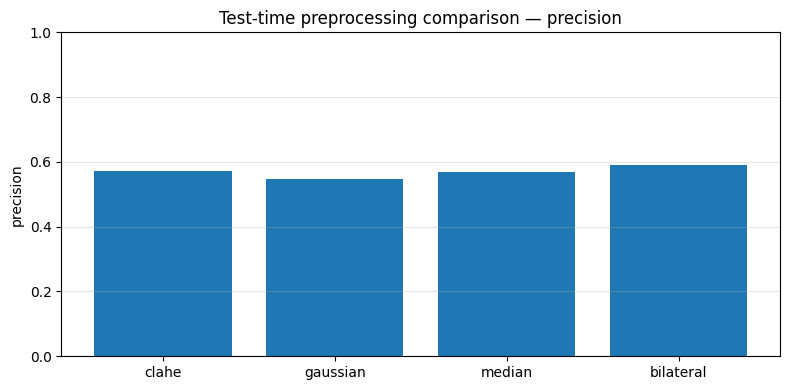

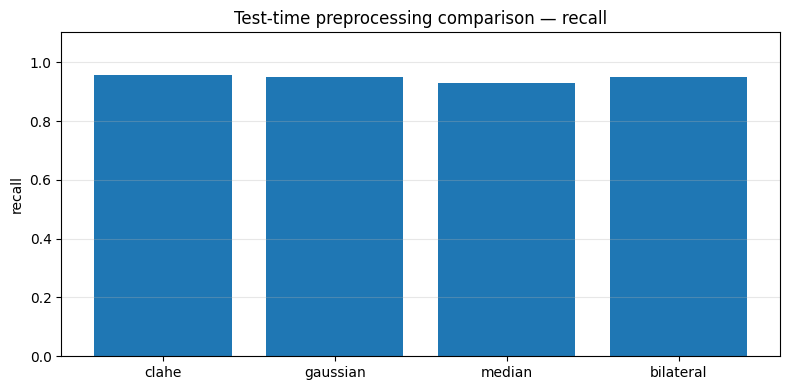

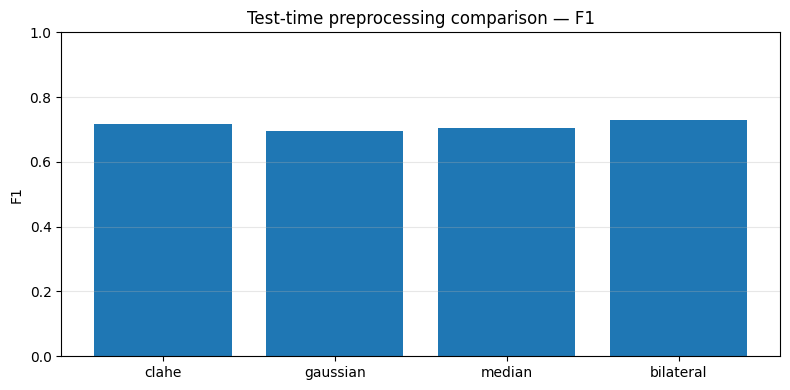

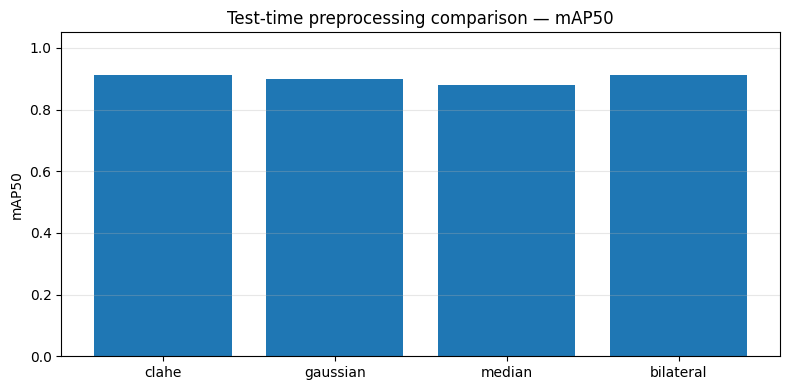

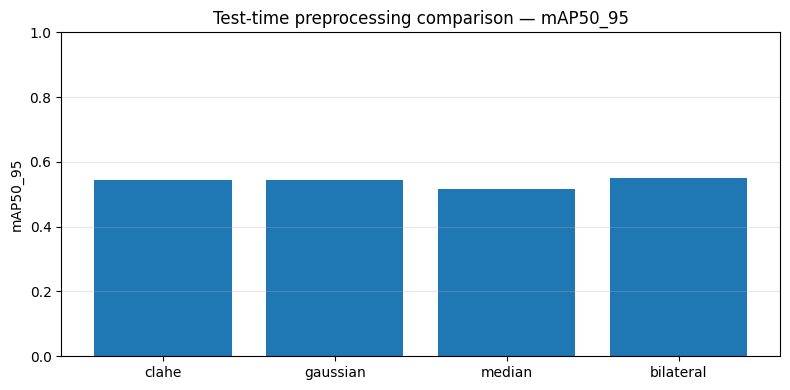

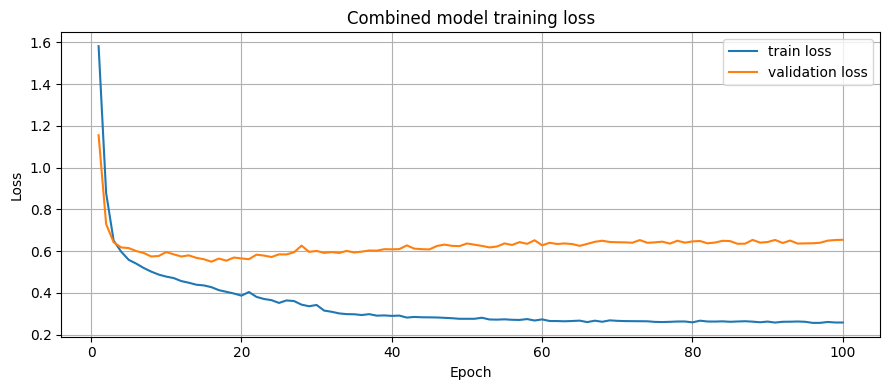

In [ ]:
for col in ["precision","recall","F1","mAP50","mAP50_95"]:
    fig,ax=plt.subplots(figsize=(8,4))
    ax.bar(metrics.method,metrics[col])
    ax.set_title("Test-time preprocessing comparison — "+col); ax.set_ylabel(col)
    ax.set_ylim(0,max(1,float(metrics[col].max())*1.15)); ax.grid(axis="y",alpha=.3)
    plt.tight_layout(); fig.savefig(OUT/f"comparison_{col}.png",dpi=150); plt.show()
hdf=pd.DataFrame(history)
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(hdf.epoch,hdf.train_loss,label="train loss")
if hdf.val_loss.notna().any(): ax.plot(hdf.epoch,hdf.val_loss,label="validation loss")
ax.set_title("Combined model training loss"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.grid(True); ax.legend(); plt.tight_layout(); fig.savefig(OUT/"combined_training_loss.png",dpi=150); plt.show()

## 11. Display 10 tested images per preprocessing method

The same combined-trained model predicts on held-out images transformed in each of the four ways. Green solid boxes = ground truth; red dashed boxes = predictions with class and confidence.

In [ ]:
from pathlib import Path
import os

print("=== 1. Current output folder ===")
out = Path("/content/BHD_new_dataset_results")
if out.exists():
    for p in out.rglob("*"):
        if p.is_file():
            print(p, f"({p.stat().st_size / (1024**2):.2f} MB)")
else:
    print("Output folder does not exist.")

print("\n=== 2. Mount Google Drive ===")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount message:", e)

print("\n=== 3. Search Drive for BHD checkpoints ===")
drive_root = Path("/content/drive/MyDrive")
if drive_root.exists():
    found = 0
    for pattern in ["*.pth", "*.pt"]:
        for p in drive_root.rglob(pattern):
            if any(word in str(p).lower()
                   for word in ["bhd", "beach", "fasterrcnn"]):
                print(p, f"({p.stat().st_size / (1024**2):.2f} MB)")
                found += 1
    if found == 0:
        print("No matching checkpoint files found.")
else:
    print("Google Drive is not accessible.")

=== 1. Current output folder ===
Output folder does not exist.

=== 2. Mount Google Drive ===
Mounted at /content/drive

=== 3. Search Drive for BHD checkpoints ===
/content/drive/MyDrive/fasterrcnn_resume.pth (0.00 MB)
/content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth (329.57 MB)
/content/drive/MyDrive/beach_human_detection_outputs/fasterrcnn_best.pth (329.62 MB)
/content/drive/MyDrive/beach_human_detection_outputs/fasterrcnn_last.pth (329.63 MB)
/content/drive/MyDrive/beach_human_detection_corrected/fasterrcnn_last.pth (329.63 MB)
/content/drive/MyDrive/beach_human_detection_corrected/fasterrcnn_best.pth (329.62 MB)


In [ ]:
from pathlib import Path

print("=== Searching Colab storage for new experiment checkpoints ===")

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

extensions = {".pth", ".pt", ".ckpt"}
skip_dirs = {
    "site-packages", ".cache", "node_modules",
    ".git", "torch", "tensorflow"
}

found = []

for root in search_roots:
    if not root.exists():
        continue

    for p in root.rglob("*"):
        if not p.is_file():
            continue

        if p.suffix.lower() not in extensions:
            continue

        if any(part in skip_dirs for part in p.parts):
            continue

        # Ignore the known older project checkpoints in this search summary.
        if any(name in str(p).lower() for name in [
            "beach_human_detection_outputs",
            "beach_human_detection_corrected",
            "fasterrcnn_resume"
        ]):
            continue

        found.append(p)

if found:
    for p in found:
        print(f"{p}  |  {p.stat().st_size / (1024**2):.2f} MB")
else:
    print("No other model checkpoint files found.")

print("\n=== Checking new experiment results folder ===")
for folder in [
    Path("/content/BHD_new_dataset_results"),
    Path("/content/drive/MyDrive/BHD_new_dataset_results")
]:
    print(f"\n{folder}:")
    if folder.exists():
        for p in folder.rglob("*"):
            if p.is_file():
                print(" ", p, f"({p.stat().st_size / 1024**2:.2f} MB)")
    else:
        print("  Folder not found.")

=== Searching Colab storage for new experiment checkpoints ===
No other model checkpoint files found.

=== Checking new experiment results folder ===

/content/BHD_new_dataset_results:
  Folder not found.

/content/drive/MyDrive/BHD_new_dataset_results:
  Folder not found.


In [ ]:
# ============================================================
# DISPLAY 10 TEST IMAGES TOTAL FOR ALL 4 PREPROCESSING METHODS
# Automatically loads a saved checkpoint if model is not in memory
# ============================================================

import torch
import torchvision
import matplotlib.pyplot as plt
import random
from pathlib import Path
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# -------------------- SETTINGS --------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
METHODS = ["clahe", "gaussian", "median", "bilateral"]
CLASS_NAMES = {0: "Human on Land", 1: "Human in Water"}
CONFIDENCE_THRESHOLD = 0.5
TOTAL_IMAGES = 10

print("Device:", DEVICE)

# -------------------- FIND TRAINED MODEL --------------------
# Reuse the trained model if it still exists in memory.
if "model" not in globals():

    print("Trained model variable not found. Searching for checkpoint...")

    search_dirs = [
        Path("/content/BHD_new_dataset_results"),
        Path("/content/drive/MyDrive/BHD_new_dataset_results"),
    ]

    checkpoints = []
    for folder in search_dirs:
        if folder.exists():
            checkpoints.extend(folder.rglob("*.pth"))

    # Prefer a best-model checkpoint, if available.
    best_files = [
        p for p in checkpoints
        if "best" in p.name.lower()
    ]

    if best_files:
        checkpoint_path = best_files[0]
    elif checkpoints:
        checkpoint_path = max(checkpoints, key=lambda p: p.stat().st_mtime)
    else:
        raise FileNotFoundError(
            "No saved checkpoint was found. The trained model may still "
            "need to be saved or restored. This cell will not retrain it."
        )

    print("Loading checkpoint:", checkpoint_path)

    weights = torchvision.models.detection.FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn_v2(
        weights=None,
        weights_backbone=None
    )

    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 3)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # Support checkpoints saved as either a raw state dict or a dictionary.
    if isinstance(checkpoint, dict):
        if "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        elif "model_state" in checkpoint:
            state_dict = checkpoint["model_state"]
        elif "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        else:
            state_dict = checkpoint
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict)
    model = model.to(DEVICE)

model.eval()
print("Model is ready.")

# -------------------- CHECK TEST DATASET --------------------
if "TEST_DIR" not in globals():
    raise NameError(
        "TEST_DIR is not defined. Run the dataset setup cell first "
        "so the notebook knows where your test images are."
    )

if "BHDDataset" not in globals():
    raise NameError(
        "BHDDataset is not defined. Run the dataset class definition cell first."
    )

# -------------------- SELECT 10 IMAGES OVERALL --------------------
# Approximately balanced across the four preprocessing methods.
quotas = [3, 3, 2, 2]
selected = []

for method, quota in zip(METHODS, quotas):
    ds = BHDDataset(TEST_DIR, method)
    if len(ds) == 0:
        print(f"Warning: no test images found for {method}.")
        continue

    chosen = random.sample(range(len(ds)), min(quota, len(ds)))
    selected.extend((method, ds, idx) for idx in chosen)

if not selected:
    raise RuntimeError("No test images were found. Check TEST_DIR and dataset setup.")

print(f"\nDisplaying {len(selected)} test images total.")

# -------------------- DRAW GROUND TRUTH AND PREDICTIONS --------------------
for image_number, (method, ds, idx) in enumerate(selected, start=1):
    img, target = ds[idx]

    with torch.no_grad():
        prediction = model([img.to(DEVICE)])[0]

    image_np = img.detach().cpu().permute(1, 2, 0).numpy()

    # If image values are normalized, bring them into display range.
    image_np = image_np.clip(0, 1)

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(image_np)
    ax.set_title(f"Image {image_number}/{len(selected)} — {method.upper()}")
    ax.axis("off")

    # Ground truth boxes: green
    for box, label in zip(target["boxes"].cpu().numpy(),
                          target["labels"].cpu().numpy()):
        # Torchvision label 1 = land, label 2 = water
        semantic_id = int(label) - 1
        x1, y1, x2, y2 = box

        ax.add_patch(plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="lime", linewidth=2
        ))
        ax.text(
            x1, max(0, y1 - 5),
            f"GT: {CLASS_NAMES.get(semantic_id, 'Unknown')}",
            color="black", fontsize=8,
            bbox=dict(facecolor="lime", alpha=0.85, pad=2)
        )

    # Predictions: red
    boxes = prediction["boxes"].detach().cpu().numpy()
    labels = prediction["labels"].detach().cpu().numpy()
    scores = prediction["scores"].detach().cpu().numpy()

    found_prediction = False
    for box, label, score in zip(boxes, labels, scores):
        if score < CONFIDENCE_THRESHOLD:
            continue

        found_prediction = True
        semantic_id = int(label) - 1
        x1, y1, x2, y2 = box

        ax.add_patch(plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="red", linewidth=2
        ))
        ax.text(
            x1, min(y2, y1 + 15),
            f"Pred: {CLASS_NAMES.get(semantic_id, 'Unknown')} ({score:.2f})",
            color="white", fontsize=8,
            bbox=dict(facecolor="red", alpha=0.85, pad=2)
        )

    if not found_prediction:
        ax.text(
            0.02, 0.02, "No prediction above confidence threshold",
            transform=ax.transAxes, color="white",
            bbox=dict(facecolor="black", alpha=0.75)
        )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

print("\nTest-image visualization completed.")

Device: cuda
Trained model variable not found. Searching for checkpoint...


FileNotFoundError: No saved checkpoint was found. The trained model may still need to be saved or restored. This cell will not retrain it.

## 12. Package results and checkpoints

In [ ]:
zip_path=Path("/content/BHD_new_dataset_results.zip")
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p,p.relative_to(OUT.parent))
print("Results archive:",zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("Download the archive from",zip_path)

## Important interpretation notes

- The existing `fasterrcnn_best.pth` is never loaded or overwritten.
- One new model is trained for **100 epochs total**, using randomly selected preprocessing methods during training.
- Evaluation uses the test split if available; otherwise validation is used and the selected split is printed.
- Precision/recall/F1 use confidence ≥0.50 and class-aware IoU ≥0.50. mAP is computed separately.
- Ground-truth annotations come from the dataset; model predictions are not guaranteed to match perfectly.
- If the class names in `data.yaml` do not match the expected names, the notebook stops rather than silently swapping land/water labels.